In [1]:
import tensorflow
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print(X_train.shape, y_train.shape)

c:\Users\Edward\Desktop\python\Lib\site-packages\google\api_core\_python_version_support.py:263: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


(60000, 28, 28) (60000,)


## Preprocessing

In [2]:
# scaling
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

# Conv layer required channels
X_train_scaled = X_train_scaled.reshape(-1, 28, 28, 1)
X_test_scaled = X_test_scaled.reshape(-1, 28, 28, 1)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


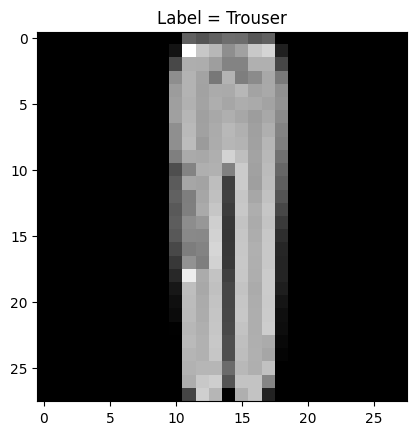

In [3]:
label = {0:'T-shirt/Top',
         1:'Trouser',
         2:'Pullover',
         3:'Dress',
         4:'Coat',
         5:'Sandal',
         6:'Shirt',
         7:'Sneaker',
         8:'Bag',
         9:'Ankle Boot'}

plt.imshow(X_train[1000], cmap='gray')
plt.title(f'Label = {label[y_train[1000]]}')
plt.show()

## CNN

In [4]:
from tensorflow.keras import layers, Sequential

# CNN: Conv(32) -> Pool -> Conv(64) -> Pool -> Flatten -> Dense(10)
cnn_model = Sequential([

    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu',
                  input_shape=(X_train_scaled.shape[1], X_train_scaled.shape[2], X_train_scaled.shape[3])),
    layers.MaxPooling2D(pool_size=(2,2)),

    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),

    layers.MaxPooling2D(pool_size=(2,2)),

    layers.Flatten(),

    layers.Dense(units=10, activation='softmax')
])

c:\Users\Edward\Desktop\python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

## compile and fit

In [6]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # y is plain int labels (0-9)
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    X_train_scaled, y_train,
    epochs = 10,
    batch_size = 64,
    validation_split=0.1
)


Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8075 - loss: 0.5422 - val_accuracy: 0.8448 - val_loss: 0.4285
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8724 - loss: 0.3560 - val_accuracy: 0.8792 - val_loss: 0.3375
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8874 - loss: 0.3140 - val_accuracy: 0.8838 - val_loss: 0.3194
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8952 - loss: 0.2888 - val_accuracy: 0.8980 - val_loss: 0.2815
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9035 - loss: 0.2661 - val_accuracy: 0.8948 - val_loss: 0.2808
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9100 - loss: 0.2474 - val_accuracy: 0.9000 - val_loss: 0.2805
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9171 - loss: 0.2337 - val_accuracy: 0.8883 - val_loss: 0.3068
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9214 - loss: 0.2197 - val_acc

## training vs validation asccuracy and loss

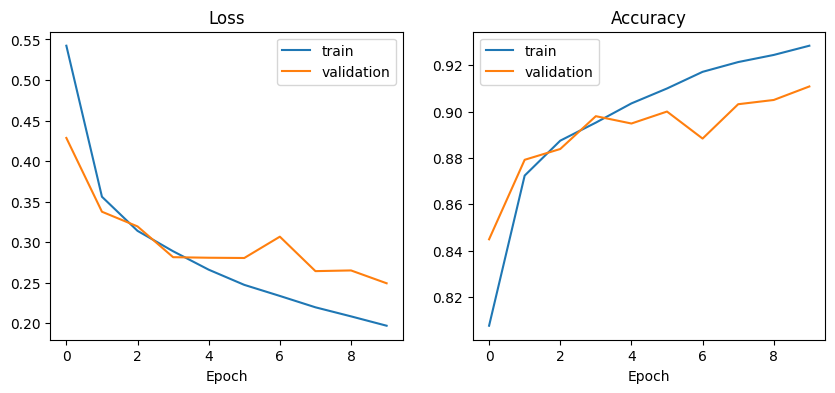

In [7]:
import matplotlib.pyplot as plt

h = cnn_history.history          # dict: loss, accuracy, val_loss, val_accuracy

fig, ax = plt.subplots(1, 2, figsize=(10, 4))   # two plots side by side

ax[0].plot(h['loss'], label='train')
ax[0].plot(h['val_loss'], label='validation')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(h['accuracy'], label='train')
ax[1].plot(h['val_accuracy'], label='validation')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.show()